# Part 2: Single Stock Analysis Notebook
Author: Ada Kam

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates
import sqlite3
from pathlib import Path
from IPython.display import display

%matplotlib inline


plt.style.use('seaborn-v0_8-whitegrid')
import scrapbook as sb

## 2.1 Parameters

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = 'data/data.db'
volatility_window = 20

In [3]:
# Parameters
ticker = "GS"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "C:\\Users\\adaka\\github\\UCB-MFE-python-preprogram-2026-winter\\Homeworks\\HW2\\Ada_Kam\\data\\data.db"
volatility_window = 20


## 2.2 Data Loading

In [4]:
MIN_PRICES=21
database = Path(db_path)

if not database.is_file():
    raise FileNotFoundError(f'Download the bCourses database, run 01_data_cleaning.ipynb, and place it at {database.resolve()}')
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError(f"Start date not before end date")
if not isinstance(volatility_window, int) or isinstance(volatility_window, bool) or volatility_window < 2:
    raise ValueError(f"volatility_window should be integer >= 2")

conn = sqlite3.connect(database.resolve().as_uri() + '?mode=ro', uri=True)


query = """SELECT ts, open, high, low, close, adj_close, volume, ticker
            FROM ohlc_hw_cleaned
            WHERE ticker = ?
            AND ts BETWEEN ? AND ?
            ORDER BY ts"""

def validate_px(prices, ticker, min_prices=MIN_PRICES):
    """Raise error if missing price, non positive prices, duplicated dates, any data quality issues"""
    if len(prices) < min_prices:
        raise ValueError(f"{len(prices)} prices found, need at least {min_prices} prices for {min_prices-1} returns")
    price_cols = ['open', 'high', 'low', 'close', 'adj_close']
    problems = []
    if prices[price_cols].isna().any().any():
        problems.append(f"{int(prices[price_cols].isna().sum().sum())} missing prices")
    if (prices[price_cols] <= 0).any().any() or np.isinf(prices[price_cols]).any().any():
        problems.append("non-positive or infinite prices")
    if prices['ts'].duplicated().any():
        problems.append(f"{int(prices['ts'].duplicated().sum())} duplicate dates")
    if problems:
        raise ValueError(f"Data quality checks failed for {ticker}: " + "; ".join(problems))


def load_px(conn, ticker, start_dt, end_dt):
    """get data for ticker between start_dt and end_dt from database"""
    return pd.read_sql_query(query, conn, params=(ticker, start_dt, end_dt), parse_dates=['ts'])

prices = load_px(conn, ticker, start_date, end_date)
validate_px(prices, ticker)

display(prices.head(3), prices.tail(3))
print(f"{ticker} from {prices['ts'].min():%Y-%m-%d} to {prices['ts'].max():%Y-%m-%d}: {len(prices)} trading days")


,ts,open,high,low,close,adj_close,volume,ticker
0,2024-06-03,458.87,458.87,450.20,454.98,452.30,1930715,GS
1,2024-06-04,450.50,457.71,449.21,455.30,452.62,1835000,GS
2,2024-06-05,457.55,463.02,457.50,461.68,458.96,1678900,GS


,ts,open,high,low,close,adj_close,volume,ticker
94,2024-10-16,530.00,536.22,525.98,529.86,529.86,2649018,GS
95,2024-10-17,531.24,535.29,528.23,529.00,529.00,2123514,GS
96,2024-10-18,529.39,530.77,526.87,528.50,528.50,1762087,GS


GS from 2024-06-03 to 2024-10-18: 97 trading days


## 2.3 Calculate Risk Metrics

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns"""
    return np.log(prices / prices.shift(1))


In [6]:
def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility"""

    if returns.notna().sum() < window:
        print(f"Insufficient returns for a {window}-day volatility: {returns.notna().sum()} available")
        return pd.Series(np.nan, index=returns.index)
    
    return returns.rolling(window).std()*np.sqrt(252)
    # Hint: returns.rolling(window).std() * np.sqrt(252)


In [7]:
def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    cum_max = prices.cummax()
    return (prices - cum_max)/cum_max
    # Hint:
    # 1. Calculate cumulative max price
    # 2. Drawdown = (price - cum_max) / cum_max


In [8]:
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio"""
    returns = returns.dropna()
    mean_return = returns.mean()
    std_return = returns.std()

    if len(returns) < 2 or not np.isfinite(std_return) or std_return == 0:
        return np.nan

    return (mean_return * 252 - risk_free_rate) / (std_return * np.sqrt(252))

    # Hint: (mean_return * 252 - rf) / (std_return * sqrt(252))


In [9]:
returns = calculate_returns(prices['adj_close'])
volatility = calculate_volatility(returns, volatility_window)
dd = calculate_max_drawdown(prices['adj_close'])
max_dd = dd.min()
sharpe = calculate_sharpe_ratio(returns)

print(f"Max drawdown: {max_dd:.2%}")
print(f"{volatility_window}-day volatility: latest {volatility.iloc[-1]:.2%}, mean {volatility.mean():.2%}")
print(f"Sharpe ratio: {sharpe:.2f}" if np.isfinite(sharpe) else "Sharpe ratio: N/A")

Max drawdown: -9.83%
20-day volatility: latest 16.73%, mean 26.76%
Sharpe ratio: 1.53


## 2.4 Visualization

In [10]:
def plot_analysis(df, ticker, window=volatility_window):
    """2x2 risk report: price with 50-day MA coloured by volatility, daily returns, rolling volatility, drawdown."""
    df = df.sort_values('ts').copy()
    df['ts'] = pd.to_datetime(df['ts'])
    df = df.set_index('ts')

    adj_close=df['adj_close']
    start_date = adj_close.index.min().strftime('%Y-%m-%d')
    end_date = adj_close.index.max().strftime('%Y-%m-%d')

    returns = calculate_returns(adj_close)
    ma_50 = adj_close.rolling(window=50).mean()
    vol = calculate_volatility(returns, window)
    mean_vol = vol.mean()
    dd = calculate_max_drawdown(adj_close)
    max_dd = dd.min()
    max_dd_date = dd.idxmin()

    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=100)
    fig.suptitle(f"{ticker} Risk Analysis Report — {start_date} to {end_date}", fontsize=18, fontweight='bold', y=0.94)

    def clean_spines(ax):
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.grid(True, linestyle=':', alpha=0.5, color='#bdc3c7')

    x_min, x_max = mdates.date2num(adj_close.index[0]), mdates.date2num(adj_close.index[-1])
        
    # Top left: px chart
    ax1 = axes[0, 0]
    
    x = mdates.date2num(adj_close.index)
    y = adj_close.to_numpy()
    
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    
    seg_vol = vol.to_numpy()[1:]
    segment_colors = np.where(np.isnan(seg_vol), 'gray', np.where(seg_vol > mean_vol, '#e74c3c', '#2ecc71'))

    lc = LineCollection(segments, colors=segment_colors, linewidth=2.2, zorder=2)
    ax1.add_collection(lc)
    ax1.plot(adj_close.index, ma_50, color='#f39c12', linestyle='--', linewidth=1.8, zorder=3)
    if ma_50.notna().sum() == 0:
        ax1.text(0.5, 0.05, f"50-day MA unavailable: only {len(adj_close)} prices", transform=ax1.transAxes,
                 ha='center', fontsize=10, color='#7f8c8d')

    ax1.set_xlim(x_min, x_max)
    ax1.set_ylim(adj_close.min()*0.95, adj_close.max()*1.05)
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax1.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax1.xaxis.get_major_locator()))
    
    ax1.set_title(f"{ticker} Price and 50-day MA", fontsize=14, fontweight='bold', pad=10)
    ax1.set_ylabel("Adjusted Close Price ($)", fontsize=11)
    clean_spines(ax1)
    
    custom_price_legend = [
        Line2D([0], [0], color='#2ecc71', lw=2, label='Low Volatility (<= Mean)'),
        Line2D([0], [0], color='#e74c3c', lw=2, label='High Volatility (> Mean)'),
        Line2D([0], [0], color='#95a5a6', lw=2, label='Warm-up (NaN)'),
        Line2D([0], [0], color='#f39c12', lw=1.8, linestyle='--', label='50-day MA')
    ]
    ax1.legend(handles=custom_price_legend, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)


    ### Bottom Left
    ax2 = axes[1, 0]
    ax2.plot(vol.index, vol, color='#2980b9', linewidth=1.5, label=f'{window}-day Volatility', zorder=3)
    ax2.axhline(mean_vol, color='#d35400', linestyle='--', linewidth=1.5, label=f'Mean Vol ({mean_vol:.1%})', zorder=4)
    
    ax2.fill_between(vol.index, vol, mean_vol, where=(vol > mean_vol), facecolor='#e74c3c', alpha=0.3, interpolate=True, label='High Vol (> Mean)')
    ax2.fill_between(vol.index, vol, mean_vol, where=(vol <= mean_vol), facecolor='#2ecc71', alpha=0.3, interpolate=True, label='Low Vol (<= Mean)')

    ax2.set_xlim(x_min, x_max)
    ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax2.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax2.xaxis.get_major_locator()))
    ax2.set_title(f"{ticker} Rolling Volatility ({window}-day)", fontsize=14, fontweight='bold', pad=10)
    ax2.set_ylabel("Annualized Volatility", fontsize=11)
    clean_spines(ax2)
    ax2.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

    ## Top Right
    ax3 = axes[0, 1]
    ret = returns.dropna()
    ax3.bar(ret.index, ret, width=1.0, color=np.where(ret >= 0, '#2ecc71', '#e74c3c'), alpha=0.8)
    ax3.axhline(0, color='black', linewidth=0.8)
    ax3.set_xlim(x_min, x_max)
    ax3.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax3.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax3.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax3.xaxis.get_major_locator()))
    ax3.set_title(f"{ticker} Daily Returns", fontsize=14, fontweight='bold', pad=10)
    ax3.set_ylabel("Daily log return", fontsize=11)
    clean_spines(ax3)

    # Bottom Right
    ax4 = axes[1, 1]
    for level in np.linspace(1, 0.2, 5):
        ax4.fill_between(dd.index, dd*level, 0, color='red', alpha=0.15, linewidth=0)
    ax4.plot(dd.index, dd, color='darkred', linewidth=1.2)
    ax4.scatter(max_dd_date, max_dd, color='darkred', s=60, zorder=5)
    ax4.annotate(f"Max drawdown {max_dd:.1%}\n{max_dd_date:%Y-%m-%d}", xy=(max_dd_date, max_dd),
                 xytext=(15, -10), textcoords='offset points', fontsize=10,
                 arrowprops=dict(arrowstyle='->', color='darkred'))
    ax4.axhline(0, color='black', linewidth=0.8)
    ax4.set_xlim(x_min, x_max)
    ax4.set_ylim(min(max_dd*1.25, -0.01), 0.005)
    ax4.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax4.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax4.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax4.xaxis.get_major_locator()))
    ax4.set_title(f"{ticker} Maximum Drawdown", fontsize=14, fontweight='bold', pad=10)
    ax4.set_ylabel("Drawdown from peak", fontsize=11)
    clean_spines(ax4)


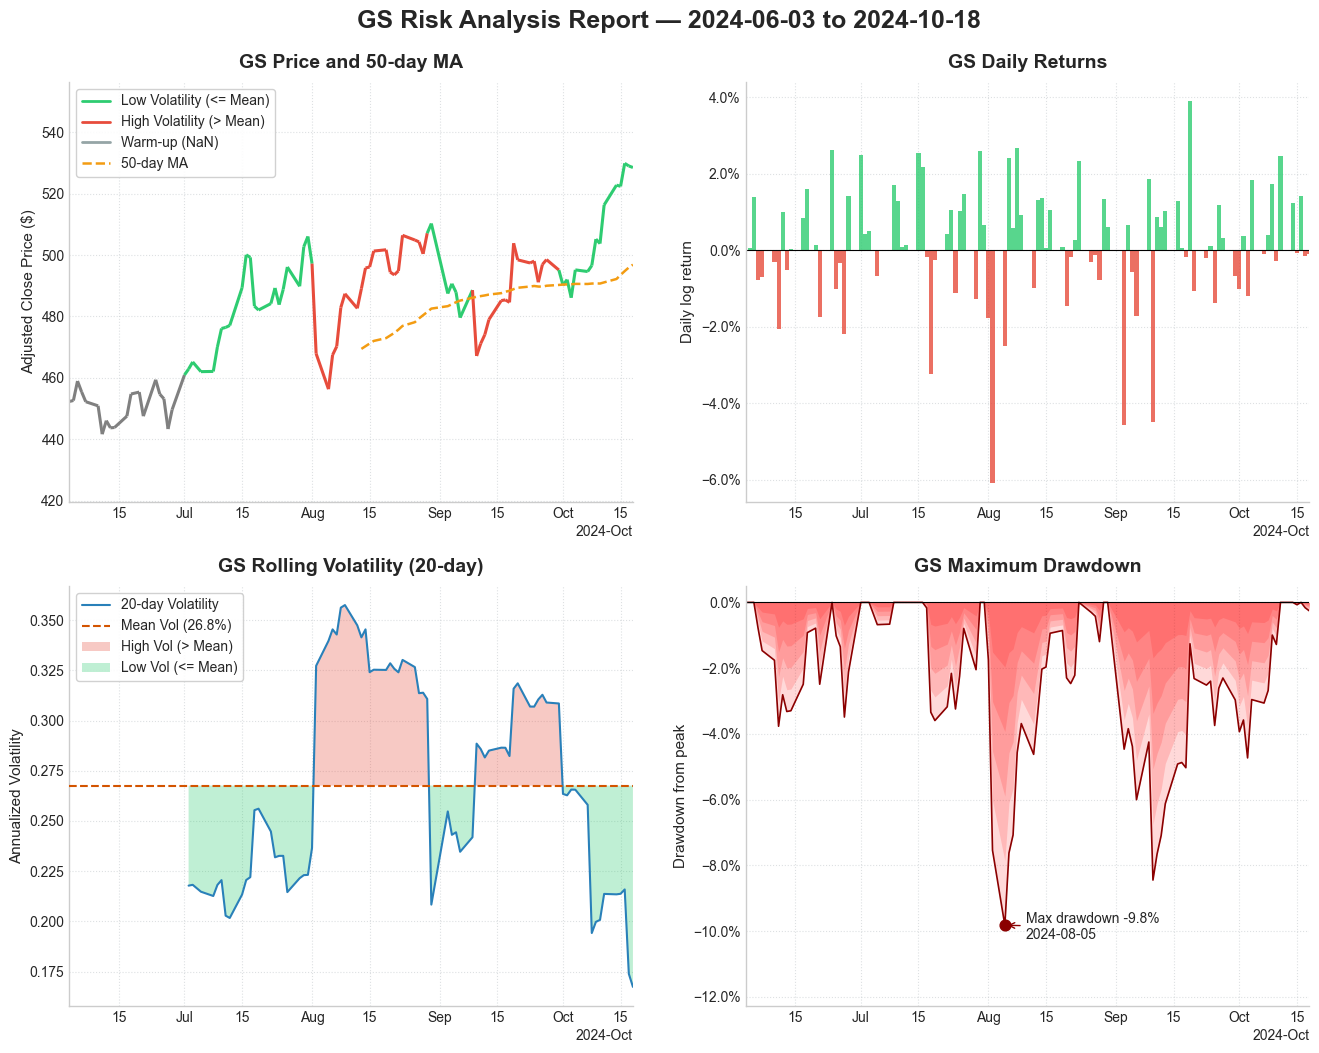

In [11]:
plot_analysis(prices, ticker, volatility_window)

## 2.5 Summary Statistics Table

In [12]:
def summary(data):
    """Summary statistics as fractions (Sharpe as a ratio); NaN where a statistic is undefined."""
    adj_close = data['adj_close']
    returns = calculate_returns(adj_close).dropna()
    total_return = (adj_close.iloc[-1]/adj_close.iloc[0])-1
    ann_return = np.exp(returns.sum() * 252 / len(returns)) - 1
    ann_vol = returns.std() * np.sqrt(252)
    sharpe = calculate_sharpe_ratio(returns)
    dd = calculate_max_drawdown(adj_close)
    max_dd = dd.min()
    best_day = returns.max()
    worst_day = returns.min()
    pos_days = (returns > 0).mean()
    avg_up = returns[returns>0].mean()
    avg_down = returns[returns<0].mean()

    metrics = [
        "Total Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown",
        "Best Day",
        "Worst Day",
        "Positive Days",
        "Average Up Day",
        "Average Down Day"
    ]

    values = [total_return, ann_return, ann_vol, sharpe, max_dd,
              best_day, worst_day, pos_days, avg_up, avg_down]

    return pd.Series(values, index=metrics, name="Value")


In [13]:
def format_summary(stats):
    """Format summar y table to hsow 2 dp"""
    signed = {'Total Return', 'Annualized Return', 'Maximum Drawdown', 'Best Day', 'Worst Day',
              'Average Up Day', 'Average Down Day'}
    def fmt(metric, value):
        if not np.isfinite(value):
            return 'N/A'
        if metric == 'Sharpe Ratio':
            return f"{value:.2f}"
        return f"{value:+.2%}" if metric in signed else f"{value:.2%}"
    return pd.DataFrame({'Value': [fmt(m, v) for m, v in stats.items()]}, index=stats.index.rename('Metric'))

In [14]:
summary_df = summary(prices)
display(format_summary(summary_df))

sb.glue('summary', {
    'ticker': ticker,
    'first_date': f"{prices['ts'].min():%Y-%m-%d}",
    'last_date': f"{prices['ts'].max():%Y-%m-%d}",
    'n_days': len(prices),
    'avg_daily_return': float(returns.mean()),
    'avg_volatility': float(volatility.mean()),
    'max_drawdown': float(max_dd),
    'sharpe_ratio': float(sharpe),
    'total_return': float(prices['adj_close'].iloc[-1] / prices['adj_close'].iloc[0] - 1),
})

conn.close()

,Value
Metric,
Total Return,+16.85%
Annualized Return,+50.49%
Annualized Volatility,25.37%
Sharpe Ratio,1.53
Maximum Drawdown,-9.83%
Best Day,+3.90%
Worst Day,-6.08%
Positive Days,58.33%
Average Up Day,+1.14%
